# Rain tomorrow (v2)

<a href="https://colab.research.google.com/github/Aadharsh21/ML-Projects/blob/main/notebooks/01-rain-tomorrow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Will it rain tomorrow? Given one day of readings from an Australian weather station (temperature, humidity,
pressure, wind, cloud, sunshine), predict whether more than 1 mm of rain falls by 9am the next day.

The first version of this project ([`notebooks/v1/LOGISTICWEATHER.ipynb`](v1/LOGISTICWEATHER.ipynb)) trained a
logistic regression and scored 84.2% on 2016-2017. This version keeps the same time-based test set so the numbers
compare directly, and then:

1. **fixes a leak** in v1's preprocessing, which was fitted on every row including the test years
2. **adds features a forecaster would look at**: 9am-to-3pm changes in pressure, humidity, cloud and temperature,
   time of year, station location, and wind directions as compass vectors
3. **switches to LightGBM**, which combines readings non-linearly and routes missing readings on its own
4. **checks calibration** so the percentages mean what they say, and **explains each forecast** with SHAP

| Graded on 2016-2017 (25,710 station-days) | v1 | v2 |
|---|---|---|
| Accuracy | 84.2% | **86.1%** |
| ROC AUC | 0.859 | **0.892** |
| Average precision | 0.688 | **0.755** |
| Brier score (lower is better) | 0.114 | **0.101** |

All of the modelling code lives in [`ml/rain.py`](../ml/rain.py); this notebook walks through it.

In [1]:
# Setup: runs from a local clone, or in Google Colab (it clones the repo first)
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("ML-Projects"):
        !git clone -q https://github.com/Aadharsh21/ML-Projects.git
    %cd ML-Projects
    %pip install -q "lightgbm>=4.3"
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import roc_auc_score

from ml import data, rain, plotting as P
from ml.evaluation import binary_metrics, bootstrap_ci, calibration_table

P.style()
pd.set_option("display.precision", 3)

## 1. The data

The [Rain in Australia](https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package) dataset: daily
observations from 49 Bureau of Meteorology stations, November 2007 to June 2017. `data.load_weather()` downloads it
from a public mirror (no Kaggle key needed), checks its SHA-256 and drops rows without a label. Older copies of the
file also carry `RISK_MM`, tomorrow's rainfall: the answer in disguise, so the loader removes it.

In [3]:
df = data.load_weather()
print(f"{len(df):,} station-days, {df['Location'].nunique()} stations, "
      f"{df['Date'].min():%b %Y} to {df['Date'].max():%b %Y}")
print(f"It rained the next day on {(df['RainTomorrow'] == 'Yes').mean():.1%} of them")
df.head(3)

140,787 station-days, 49 stations, Nov 2007 to Jun 2017
It rained the next day on 22.2% of them


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No


Many stations never record some readings. Sunshine, evaporation and cloud cover are missing for close to half of
all rows, so how a model handles gaps matters. v1 filled every gap with the column mean.

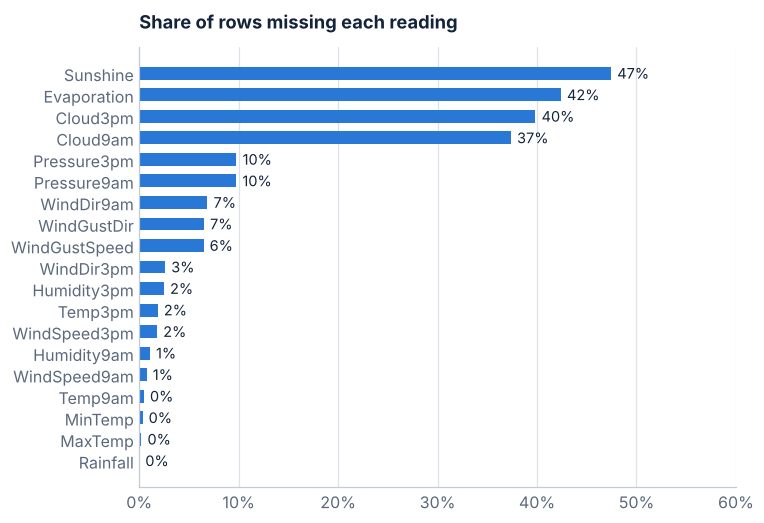

In [4]:
missing = df[rain.RAW_NUMERIC + rain.WIND_DIRS].isna().mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 5.2))
bars = ax.barh(missing.index, missing.values, color=P.BLUE, height=0.6)
P.label_bars(ax, bars, "{:.0%}")
ax.set_xlim(0, 0.6)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_title("Share of rows missing each reading")
ax.grid(axis="y", visible=False)
plt.show()

## 2. Split by time, exactly like v1

Shuffling rows would let the model peek at days next to the test days, so the split follows the calendar: train on
2007-2014, tune on 2015, and grade once on 2016-2017.

In [5]:
X = rain.features(df)
y = rain.target(df)
s = rain.split(df)
pd.DataFrame({
    name: {"rows": int(mask.sum()), "from": df.loc[mask, "Date"].min().date(),
           "to": df.loc[mask, "Date"].max().date(), "rained next day": f"{y[mask].mean():.1%}"}
    for name, mask in s.items()
}).T

,rows,from,to,rained next day
train,97988,2007-11-01,2014-12-31,22.2%
val,17089,2015-01-01,2015-12-31,20.9%
test,25710,2016-01-01,2017-06-25,22.7%


## 3. Baselines, and v1 rebuilt without the leak

Two baselines set the floor: always predicting "no rain" (right 77% of the time, because it usually doesn't rain)
and "tomorrow will be like today".

v1 fitted its imputer and scaler with `imputer.fit(read_df[numeric_cols])`, where `read_df` holds every year
including 2016-2017. The test years' averages and ranges leaked into training. Here the same model is rebuilt as a
scikit-learn `Pipeline`, so preprocessing only ever sees training rows.

In [6]:
tr, va, te = s["train"], s["val"], s["test"]
yt = y[te]
scores = {}

scores["Always no rain"] = np.zeros(te.sum())
scores["Tomorrow repeats today"] = X.loc[te, "RainToday"].to_numpy()

v1 = rain.v1_logistic().fit(df[tr], y[tr])
scores["v1: logistic regression"] = v1.predict_proba(df[te])[:, 1]

v2_logistic = rain.v2_logistic().fit(X[tr], y[tr])
scores["Logistic regression, v2 features"] = v2_logistic.predict_proba(X[te])[:, 1]

def table(scores):
    rows = {}
    for name, p in scores.items():
        m = binary_metrics(yt, p)
        rows[name] = {k: m[k] for k in ["accuracy", "roc_auc", "avg_precision", "brier"]}
    return pd.DataFrame(rows).T

table(scores)

,accuracy,roc_auc,avg_precision,brier
Always no rain,0.773,0.500,0.227,0.227
Tomorrow repeats today,0.750,0.645,0.327,0.250
v1: logistic regression,0.842,0.859,0.688,0.114
"Logistic regression, v2 features",0.843,0.860,0.683,0.114


The leak-free v1 lands on the same 84.2% the original notebook reported, so the leak was mild here. It was still a
leak: on data with more drift between years it could have inflated the score.

## 4. Features a forecaster would use

Every v2 feature is computable from the same day's readings (nothing from tomorrow):

| Feature | Why |
|---|---|
| `PressureChange`, `HumidityChange`, `TempChange`, `CloudChange` | 9am to 3pm trends: falling pressure and rising humidity signal an approaching system |
| `TempRange` | cloudy, wet days have a small gap between the high and the low |
| `SeasonSin`, `SeasonCos` | time of year on a circle, so December sits next to January |
| `Latitude`, `Longitude` | lets one model learn tropical wet seasons and southern winter rain |
| `WindGustDirSin`/`Cos` (and 9am, 3pm) | wind directions as vectors, so north-north-west sits next to north instead of being an unrelated category |

The two strongest signals, by how often it rains the next day:

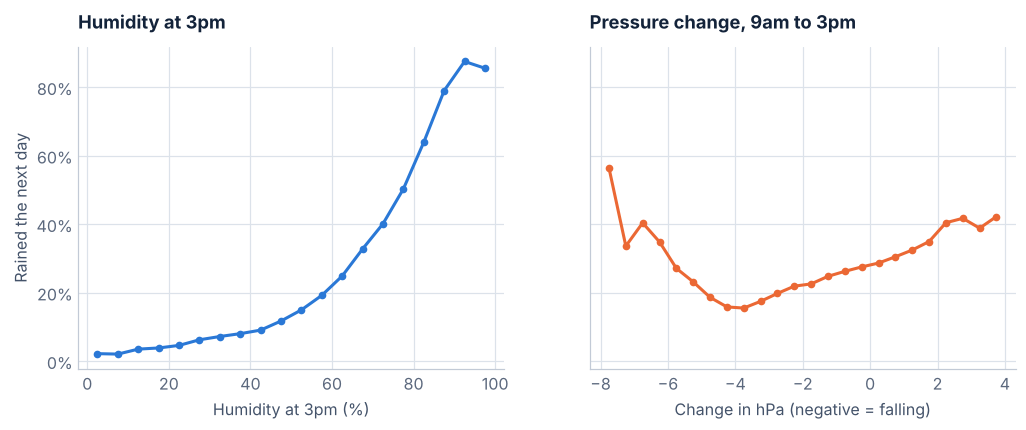

In [7]:
train_rows = df[tr].assign(pressure_change=X.loc[tr, "PressureChange"], rained=y[tr])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)

hum = train_rows.groupby(pd.cut(train_rows["Humidity3pm"], np.arange(0, 101, 5)), observed=True)["rained"].mean()
axes[0].plot([i.mid for i in hum.index], hum.values, color=P.BLUE, marker="o", ms=4)
axes[0].set_title("Humidity at 3pm")
axes[0].set_xlabel("Humidity at 3pm (%)")
axes[0].set_ylabel("Rained the next day")

pc = train_rows.groupby(pd.cut(train_rows["pressure_change"], np.arange(-8, 4.5, 0.5)), observed=True)["rained"].mean()
axes[1].plot([i.mid for i in pc.index], pc.values, color=P.ORANGE, marker="o", ms=4)
axes[1].set_title("Pressure change, 9am to 3pm")
axes[1].set_xlabel("Change in hPa (negative = falling)")
for ax in axes:
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.show()

## 5. Gradient boosted trees

LightGBM grows a few hundred shallow trees, each one correcting the last. Missing readings are sent down whichever
branch worked best during training, instead of being filled with an average. Training stops once the 2015
validation loss has not improved for 150 rounds.

Best iteration: 404 trees


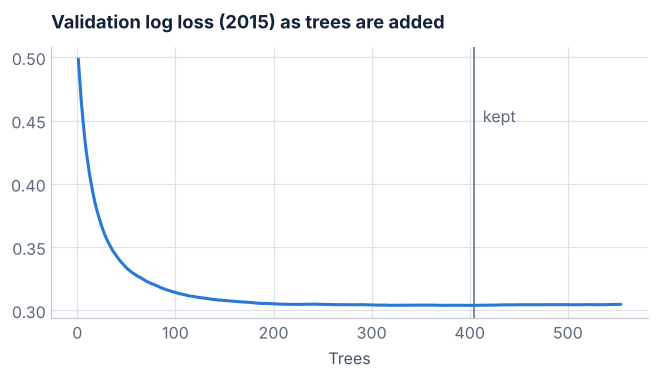

In [8]:
history = {}
train_set = lgb.Dataset(X[tr], y[tr], free_raw_data=False)
val_set = lgb.Dataset(X[va], y[va], reference=train_set)
booster = lgb.train(rain.LGB_PARAMS, train_set, num_boost_round=3000, valid_sets=[val_set],
                    callbacks=[lgb.early_stopping(150, verbose=False), lgb.record_evaluation(history)])
print(f"Best iteration: {booster.best_iteration} trees")

loss = history["valid_0"]["binary_logloss"]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(np.arange(1, len(loss) + 1), loss, color=P.BLUE)
ax.axvline(booster.best_iteration, color=P.INK_3, lw=1)
ax.annotate("kept", (booster.best_iteration, max(loss) * 0.9), xytext=(6, 0), textcoords="offset points", color=P.INK_3)
ax.set_title("Validation log loss (2015) as trees are added")
ax.set_xlabel("Trees")
plt.show()

## 6. Results on 2016-2017

In [9]:
p_test = booster.predict(X[te], num_iteration=booster.best_iteration)
scores["v2: LightGBM"] = p_test
results = table(scores)
results

,accuracy,roc_auc,avg_precision,brier
Always no rain,0.773,0.500,0.227,0.227
Tomorrow repeats today,0.750,0.645,0.327,0.250
v1: logistic regression,0.842,0.859,0.688,0.114
"Logistic regression, v2 features",0.843,0.860,0.683,0.114
v2: LightGBM,0.861,0.892,0.755,0.101


v2 accuracy 86.1%, 95% bootstrap interval 85.7% to 86.5%
Wrong forecasts: 15.8% -> 13.9% (12% fewer)


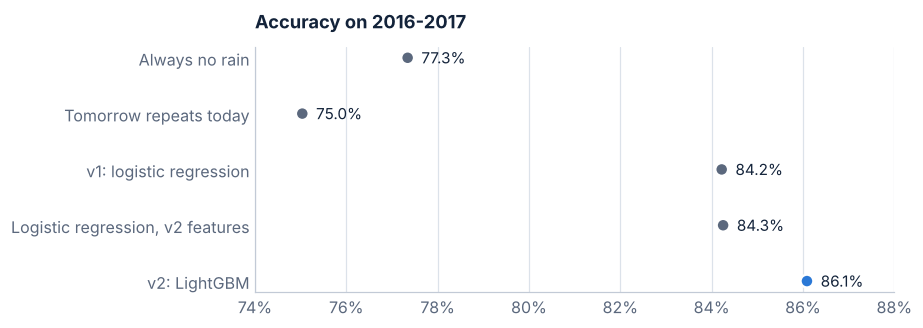

In [10]:
lo, hi = bootstrap_ci(yt, p_test, lambda a, b: float(((b >= 0.5) == a).mean()), n=500)
print(f"v2 accuracy {results.loc['v2: LightGBM', 'accuracy']:.1%}, 95% bootstrap interval {lo:.1%} to {hi:.1%}")
errors_v1 = 1 - results.loc["v1: logistic regression", "accuracy"]
errors_v2 = 1 - results.loc["v2: LightGBM", "accuracy"]
print(f"Wrong forecasts: {errors_v1:.1%} -> {errors_v2:.1%} ({1 - errors_v2 / errors_v1:.0%} fewer)")

fig, ax = plt.subplots(figsize=(7.5, 2.9))
names = list(results.index)
acc = results["accuracy"].to_numpy()
colors = [P.BLUE if n.startswith("v2") else P.INK_3 for n in names]
ax.scatter(acc, names, s=70, color=colors, ec="white", lw=1.5, zorder=3)
for a, n, c in zip(acc, names, colors):
    ax.annotate(f"{a:.1%}", (a, n), xytext=(9, 0), textcoords="offset points", va="center", color=P.INK, fontsize=10)
ax.set_xlim(0.74, 0.88)
ax.set_xticks(np.arange(0.74, 0.881, 0.02))
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.set_title("Accuracy on 2016-2017")
P.save(fig, "rain-accuracy.png")
plt.show()

Accuracy flatters any model here, because 77% comes free. ROC AUC and average precision measure how well the model
ranks rainy days above dry ones, and both jump. Notice the logistic regression with the new features barely moves:
the gain comes from letting the model combine readings (high humidity *and* falling pressure), not from the
features alone.

## 7. Can the percentages be trusted?

A forecast of 70% should come true about 70% of the time. Grouping the test days by forecast and checking how often
it rained shows the model is close to calibrated, slightly over-confident between 60% and 80%.

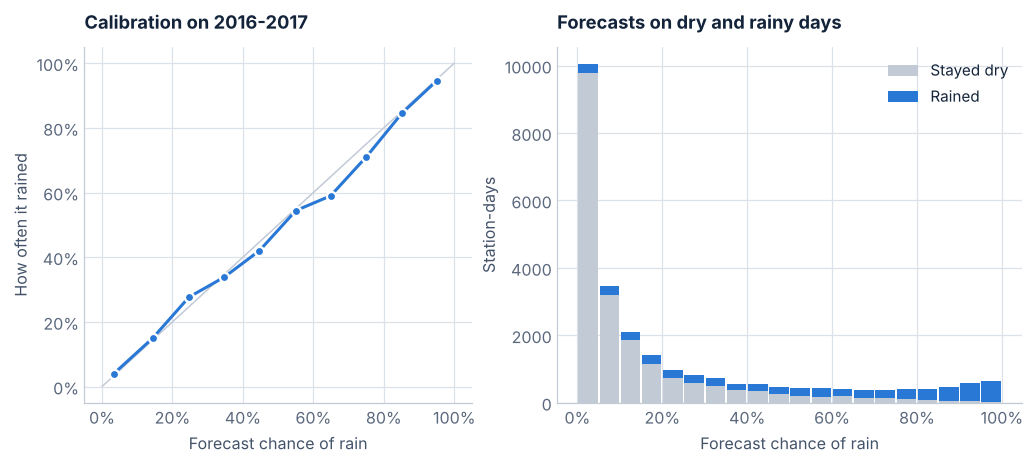

In [11]:
cal = pd.DataFrame(calibration_table(yt, p_test))
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.2]})
ax.plot([0, 1], [0, 1], color=P.GRAY, lw=1)
ax.plot(cal["mean_predicted"], cal["observed"], color=P.BLUE, marker="o", ms=6, mec="white", mew=1.5)
ax.set_xlabel("Forecast chance of rain")
ax.set_ylabel("How often it rained")
ax.set_title("Calibration on 2016-2017")
for a in (ax.xaxis, ax.yaxis):
    a.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax2.hist([p_test[yt == 0], p_test[yt == 1]], bins=np.linspace(0, 1, 21), stacked=True,
         color=[P.GRAY, P.BLUE], label=["Stayed dry", "Rained"], rwidth=0.92)
ax2.set_title("Forecasts on dry and rainy days")
ax2.set_xlabel("Forecast chance of rain")
ax2.set_ylabel("Station-days")
ax2.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax2.legend()
P.save(fig, "rain-calibration.png")
plt.show()

## 8. What the model listens to

SHAP values split each forecast (in log-odds) into one contribution per feature. Averaging their size over the test
days ranks the readings; related features (such as the sine and cosine of the season) are summed into one group.

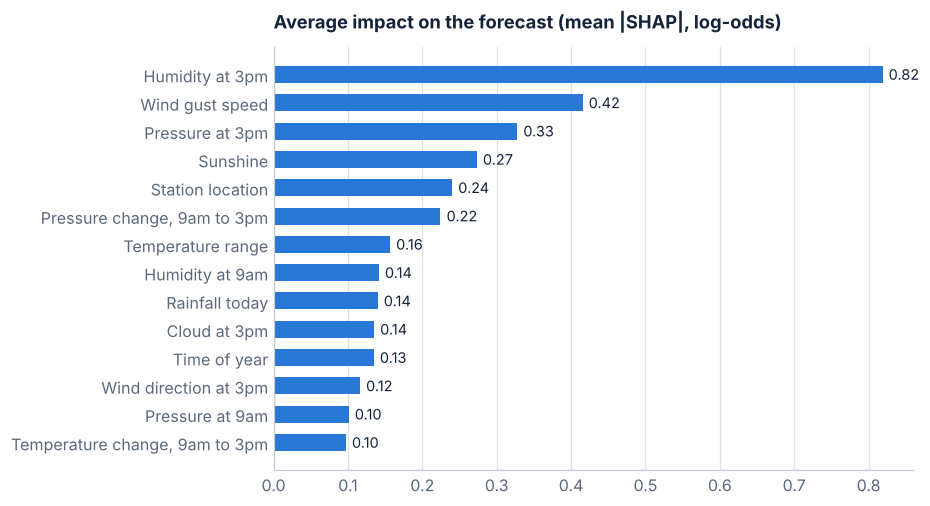

In [12]:
contrib = booster.predict(X[te], num_iteration=booster.best_iteration, pred_contrib=True)
col = {f: i for i, f in enumerate(rain.FEATURES)}
grouped = pd.DataFrame({label: contrib[:, [col[c] for c in cols]].sum(axis=1) for label, cols in rain.GROUPS})
impact = grouped.abs().mean().sort_values().tail(14)

fig, ax = plt.subplots(figsize=(7.5, 5))
bars = ax.barh(impact.index, impact.values, color=P.BLUE, height=0.6)
P.label_bars(ax, bars, "{:.2f}")
ax.grid(axis="y", visible=False)
ax.set_title("Average impact on the forecast (mean |SHAP|, log-odds)")
P.save(fig, "rain-impact.png")
plt.show()

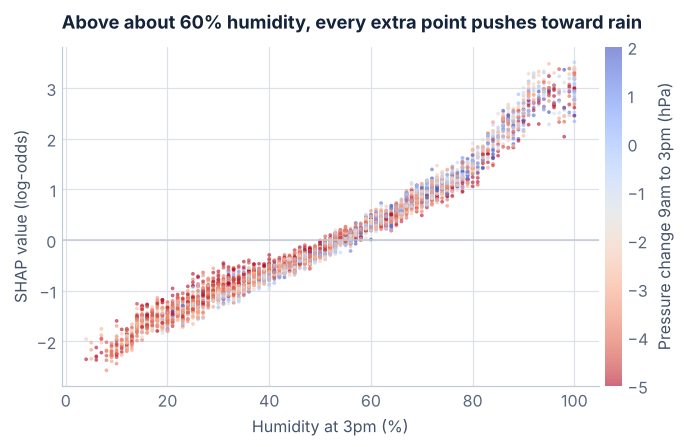

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 4))
sample = np.random.default_rng(0).choice(te.sum(), 6000, replace=False)
h3 = X.loc[te, "Humidity3pm"].to_numpy()[sample]
pc = X.loc[te, "PressureChange"].to_numpy()[sample]
sc = ax.scatter(h3, grouped["Humidity at 3pm"].to_numpy()[sample], c=np.clip(pc, -5, 2), cmap="coolwarm_r", s=6, alpha=0.6, lw=0)
cb = fig.colorbar(sc, ax=ax, pad=0.01)
cb.set_label("Pressure change 9am to 3pm (hPa)")
cb.outline.set_visible(False)
ax.axhline(0, color=P.GRAY, lw=1)
ax.set_xlabel("Humidity at 3pm (%)")
ax.set_ylabel("SHAP value (log-odds)")
ax.set_title("Above about 60% humidity, every extra point pushes toward rain")
plt.show()

## 9. One forecast, explained

Sydney on 8 July 2016. The contributions start from the average forecast and add up to this day's forecast exactly.

In [14]:
row = df.index[(df["Location"] == "Sydney") & (df["Date"] == "2016-07-08")][0]
phi = booster.predict(X.loc[[row]], num_iteration=booster.best_iteration, pred_contrib=True)[0]
base = phi[-1]
parts = pd.Series({label: sum(phi[col[c]] for c in cols) for label, cols in rain.GROUPS})
top = parts.reindex(parts.abs().sort_values(ascending=False).index).head(6)
prob = 1 / (1 + np.exp(-(base + parts.sum())))
print(f"Average forecast: {1 / (1 + np.exp(-base)):.0%}.  This day: {prob:.0%}.  "
      f"It {'rained' if y[row] else 'stayed dry'} the next day.")
reading = {
    "Humidity at 3pm": f"{df.at[row, 'Humidity3pm']:.0f}%",
    "Sunshine": f"{df.at[row, 'Sunshine']:.1f} h",
    "Wind gust speed": f"{df.at[row, 'WindGustSpeed']:.0f} km/h",
    "Temperature range": f"{df.at[row, 'MaxTemp'] - df.at[row, 'MinTemp']:.1f} °C",
    "Humidity at 9am": f"{df.at[row, 'Humidity9am']:.0f}%",
    "Station location": "Sydney",
}
pd.DataFrame({"reading": [reading.get(k, "") for k in top.index], "log-odds": top.values}, index=top.index)

Average forecast: 10%.  This day: 65%.  It rained the next day.


,reading,log-odds
Humidity at 3pm,80%,1.545
Sunshine,0.0 h,1.022
Wind gust speed,28 km/h,-0.618
Temperature range,3.2 °C,0.334
Station location,Sydney,0.311
Humidity at 9am,92%,0.290


## 10. Where it does well, and where it struggles

Accuracy by station on the test years. Dry inland stations (Woomera, Uluru, Alice Springs, Mildura) score above
92%, largely because most of their days are dry. The hardest are wet coastal stations: Albany, Norfolk Island,
Cairns and Newcastle all score under 80%. The more often a station sees rain, the lower its accuracy, which is
another reason accuracy alone is a weak measure here.

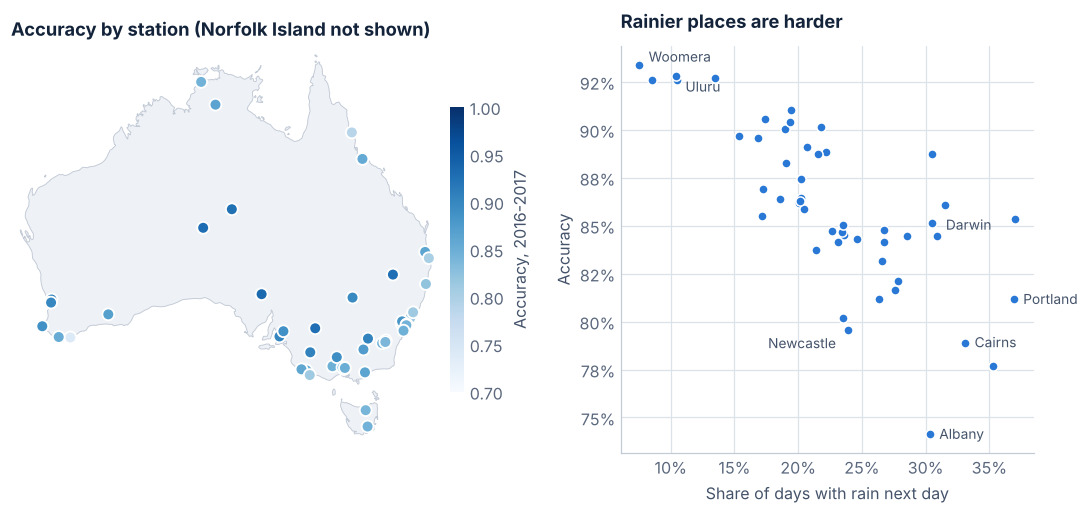

In [15]:
test_df = df[te].assign(y=yt, correct=(p_test >= 0.5) == yt)
per = test_df.groupby("Location").agg(accuracy=("correct", "mean"), rain_rate=("y", "mean"), days=("y", "size"))
per["lat"] = [rain.STATIONS[s][0] for s in per.index]
per["lon"] = [rain.STATIONS[s][1] for s in per.index]

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.25, 1]})
P.australia(ax)
mainland = per[per.index != "NorfolkIsland"]
sc = ax.scatter(mainland.lon, mainland.lat, c=mainland.accuracy, cmap="Blues", vmin=0.7, vmax=1,
                s=60, ec="white", lw=1.2, zorder=3)
cb = fig.colorbar(sc, ax=ax, shrink=0.7, pad=0.01)
cb.set_label("Accuracy, 2016-2017")
cb.outline.set_visible(False)
ax.set_title("Accuracy by station (Norfolk Island not shown)")
ax2.scatter(per.rain_rate, per.accuracy, color=P.BLUE, s=36, ec="white", lw=1)
for name, dx, dy in [("Woomera", 6, 2), ("Uluru", 6, -10), ("Albany", 6, -3), ("Cairns", 6, -3),
                     ("Newcastle", -8, -12), ("Portland", 6, -3), ("Darwin", 6, 4)]:
    ax2.annotate(rain.pretty_station(name), (per.at[name, "rain_rate"], per.at[name, "accuracy"]),
                 xytext=(dx, dy), textcoords="offset points", fontsize=9, color=P.INK_2,
                 ha="right" if dx < 0 else "left")
ax2.set_xlabel("Share of days with rain next day")
ax2.set_ylabel("Accuracy")
ax2.set_title("Rainier places are harder")
for a in (ax2.xaxis, ax2.yaxis):
    a.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
P.save(fig, "rain-stations.png")
plt.show()

## 11. Exporting for the browser

`python -m ml rain` runs everything above and writes the model to `web/public/data/rain/` as JSON. A TypeScript
engine ([`web/src/ml/lgbm.ts`](../web/src/ml/lgbm.ts)) walks the same trees and ports LightGBM's TreeSHAP, so a web
page can forecast and explain without a server. The tests check the browser matches LightGBM to 1e-9. The same
check in Python:

In [16]:
from ml.lgbm_export import export_booster, predict_raw

exported = export_booster(booster, num_iteration=booster.best_iteration)
probe = X[te].iloc[:200].to_numpy()
gap = np.abs(predict_raw(exported, probe) - booster.predict(X[te].iloc[:200], num_iteration=booster.best_iteration, raw_score=True)).max()
print(f"{len(exported['trees'])} trees exported; largest difference from LightGBM on 200 rows: {gap:.1e}")

404 trees exported; largest difference from LightGBM on 200 rows: 0.0e+00


## Limitations

- **One station, one day.** Forecasters use weather maps, satellite and radar; this model sees a single station's
  readings. 86% beats the free 77%, but it is not a weather service.
- **The label favours the afternoon.** "Rain tomorrow" counts rain from 9am today to 9am tomorrow, so afternoon
  humidity partly sees rain that has already started. That is why it dominates.
- **Old data.** The test years end in 2017, and the stations, instruments and climate keep changing.
- **Live use is approximate.** Today's readings for a live demo come from a weather model API rather than the
  stations' own instruments, a different source from the training data.